# 分析剖面图：预测热流 + DEM + 地壳结构

该 notebook 读取上一步 RBFKAN 输出的克里金预测栅格 CSV，以及分析剖面线 L1-L5，分别绘制带轮廓裁剪的预测栅格图和剖面图。

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import BoundaryNorm
from pathlib import Path
from shapely.geometry import Point, Polygon
from shapely.ops import unary_union
import pyproj
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator, RegularGridInterpolator
from pykrige.ok import OrdinaryKriging

# 中文显示配置（西文/数字用新罗马 Times New Roman，中文回退到宋体等衬线字体）
plt.rcParams["font.family"] = "serif"   # 新罗马（Times New Roman）
plt.rcParams["font.serif"] = ["Times New Roman", "SimSun", "STSong", "Noto Serif SC", "DejaVu Serif"]
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans SC", "SimSun", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 18   # 全局放大字号
plt.rcParams["axes.linewidth"] = 1.0          # 细坐标框线（期刊风格）
plt.rcParams["xtick.direction"] = "in"        # 刻度向内
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.major.size"] = 5
plt.rcParams["ytick.major.size"] = 5
plt.rcParams["axes.labelpad"] = 6
plt.rcParams["legend.frameon"] = True
plt.rcParams["legend.edgecolor"] = "0.4"
plt.rcParams["legend.fancybox"] = False

# 地壳深度垂直放大倍数（用于放大分层变化，刻度仍标注真实 km）
DEPTH_EXAG = 3.0

# 克里金插值参数
KRIG_MODEL = "linear"      # 克里金变差函数模型（linear/spherical/…）
KRIG_N_CLOSEST = 30        # 每个待估点使用的最近邻数据点数（局部克里金）

# 热导率 / LAB 双线性插值数据（grid_0.2deg.xlsx）
TC_COL = "Thermal Conductivity （mW/K/m/）"
LAB_COL = "LAB"
# 生热率数据（Heat_production.xlsx）
HEAT_PRODUCT_COL = "Heat production (mW/m3)"

pyproj.datadir.set_data_dir(r"C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj")

workspace_root = Path(r"c:\KAN-OLS-SHF\code")
grid_xls = (workspace_root / "../output/grid_0.2deg.xlsx").resolve()
heat_xls = (workspace_root / "../data/Heat_production.xlsx").resolve()
out_dir = (workspace_root / "../output/analysis_line_profiles").resolve()
out_dir.mkdir(parents=True, exist_ok=True)

grid_csv = (workspace_root / "../output/train/rbfkan/combined_rasters/raster_a_shf.csv").resolve()
study_shp = (workspace_root / "../data/eastChinaLine.shp").resolve()
dem_xls = (workspace_root / "../data/DEM.xls").resolve()
crust_csv = (workspace_root / "../data/CRUST1.0/crust1.0-xyz/crust1_merged.csv").resolve()
line_dir = (workspace_root / "../data/analysisLine").resolve()
tlf_shp = (workspace_root / "../tectonicPlate/TLF.shp").resolve()   # 郯庐断裂带
tb_shp = (workspace_root / "../tectonicPlate/TB.shp").resolve()     # 构造块体边界（TB）

# CRUST1.0 地壳分层：(中文名, 原始列名, CSV 输出列名)
CRUST_LAYERS = [
    ("Upper sediment", "th3", "upper_sediment"),
    ("Middle sediment", "th4", "middle_sediment"),
    ("Lower sediment", "th5", "lower_sediment"),
    ("Upper crust",   "th6", "upper_crust"),
    ("Middle crust",   "th7", "middle_crust"),
    ("Lower crust",   "th8", "lower_crust"),
]
CRUST_LAYER_COLORS = ["#E4C795", "#D3AC78", "#BC9159", "#D97C5A", "#C2604E", "#A44040"]

print("Grid CSV:", grid_csv)
print("Grid xls (TC/LAB):", grid_xls)
print("Study area shapefile:", study_shp)
print("DEM file:", dem_xls)
print("Crust file:", crust_csv)
print("Line dir:", line_dir)
print("TLF file:", tlf_shp)


def read_gdf_wgs84(path):
    gdf = gpd.read_file(path)
    if gdf.crs is None:
        gdf = gdf.set_crs("EPSG:4326", allow_override=True)
    elif str(gdf.crs) != "EPSG:4326":
        gdf = gdf.to_crs("EPSG:4326")
    return gdf


def read_line_gdf(path):
    gdf = gpd.read_file(path)
    if gdf.crs is None:
        gdf = gdf.set_crs("EPSG:3857", allow_override=True)
    elif str(gdf.crs) != "EPSG:4326":
        gdf = gdf.to_crs("EPSG:4326")
    return gdf


def get_mask_polygon(shp_path):
    gdf = read_gdf_wgs84(shp_path)
    union_geom = unary_union(gdf.geometry)
    if union_geom.geom_type in ("LineString", "MultiLineString"):
        if union_geom.geom_type == "LineString" and union_geom.is_ring:
            return Polygon(union_geom.coords)
        polys = [Polygon(line.coords) for line in (union_geom.geoms if union_geom.geom_type == "MultiLineString" else [union_geom]) if getattr(line, "is_ring", False)]
        return unary_union(polys) if polys else None
    return union_geom if union_geom.geom_type in ("Polygon", "MultiPolygon") else None


def clip_line_to_mask(line_geom, mask_poly):
    if mask_poly is None or line_geom is None or getattr(line_geom, "is_empty", False):
        return None
    clipped = line_geom.intersection(mask_poly)
    if getattr(clipped, "is_empty", False):
        return None
    return clipped


def _flatten_lines(geom):
    """将几何展平为 LineString 列表（支持 LineString / MultiLineString / GeometryCollection）。"""
    if geom is None or getattr(geom, "is_empty", False):
        return []
    if geom.geom_type == "LineString":
        return [geom]
    if geom.geom_type in ("MultiLineString", "GeometryCollection"):
        parts = []
        for g in geom.geoms:
            parts.extend(_flatten_lines(g))
        return parts
    return []


def longest_line(geom):
    """返回几何中最长的一段 LineString（无则返回 None）。"""
    parts = [p for p in _flatten_lines(geom) if p.length > 0]
    return max(parts, key=lambda p: p.length) if parts else None


def sample_line_points(line_geom, step_deg=0.02, mode="longest"):
    """沿线采样。mode='longest' 只取最长一段；mode='all' 逐段采样所有部分并按累积距离拼接。"""
    parts = [p for p in _flatten_lines(line_geom) if p.length > 0]
    if not parts:
        return pd.DataFrame(columns=["lon", "lat", "distance_km"])
    if mode == "longest":
        parts = [max(parts, key=lambda p: p.length)]

    all_frames = []
    offset_km = 0.0
    for part in parts:
        total_len = part.length
        n = max(2, int(np.ceil(total_len / step_deg)) + 1)
        pts = []
        for i in range(n):
            dist = (i / (n - 1)) * total_len
            p = part.interpolate(dist)
            pts.append((p.x, p.y))
        df = pd.DataFrame(pts, columns=["lon", "lat"])
        df["distance_km"] = 0.0
        for i in range(1, len(df)):
            dx = df.loc[i, "lon"] - df.loc[i - 1, "lon"]
            dy = df.loc[i, "lat"] - df.loc[i - 1, "lat"]
            df.loc[i, "distance_km"] = df.loc[i - 1, "distance_km"] + np.hypot(dx, dy) * 111.0
        df["distance_km"] = df["distance_km"] + offset_km
        offset_km = df["distance_km"].iloc[-1]
        all_frames.append(df)

    return pd.concat(all_frames, ignore_index=True)


def build_regular_grid(df, lon_col, lat_col, value_col):
    """将 (lon, lat, value) 表转成规则网格，返回 (lon_vals, lat_vals, value_2d)。向量化实现。"""
    lon_vals = np.sort(np.unique(df[lon_col].astype(float)))
    lat_vals = np.sort(np.unique(df[lat_col].astype(float)))
    grid = np.full((len(lat_vals), len(lon_vals)), np.nan, dtype=float)
    sub = df[[lon_col, lat_col, value_col]].dropna()
    lon_idx = np.searchsorted(lon_vals, sub[lon_col].to_numpy())
    lat_idx = np.searchsorted(lat_vals, sub[lat_col].to_numpy())
    grid[lat_idx, lon_idx] = sub[value_col].to_numpy()
    return lon_vals, lat_vals, grid


def build_grid_interpolator(lons, lats, values):
    """从规则网格构建矢量插值器（三角化只做一次），返回 callable(xi: Nx2 [lon,lat]) -> (N,)。
    线性插值为主，线性失败处用最近邻填充。"""
    lon_grid, lat_grid = np.meshgrid(lons, lats)
    valid = np.isfinite(values)
    pts = np.column_stack([lon_grid[valid], lat_grid[valid]])
    vals = values[valid]
    if len(pts) == 0:
        return lambda xi: np.full(len(np.asarray(xi, dtype=float)), np.nan)
    lin = LinearNDInterpolator(pts, vals, fill_value=np.nan)
    near = NearestNDInterpolator(pts, vals)

    def interp(xi):
        xi = np.asarray(xi, dtype=float).reshape(-1, 2)
        res = np.asarray(lin(xi), dtype=float).reshape(-1)
        nan_mask = np.isnan(res)
        if nan_mask.any():
            res[nan_mask] = np.asarray(near(xi[nan_mask]), dtype=float).reshape(-1)
        return res

    return interp


def build_bilinear_interpolator(lons, lats, values):
    """从规则网格构建双线性插值器（RegularGridInterpolator, method='linear'）。
    lons/lats 需严格递增（build_regular_grid 已排序）。
    返回 callable(xi: Nx2 [lon,lat]) -> (N,)。"""
    lon_g = np.asarray(lons, dtype=float)
    lat_g = np.asarray(lats, dtype=float)
    v = np.asarray(values, dtype=float)
    if len(lon_g) < 2 or len(lat_g) < 2:
        return lambda xi: np.full(len(np.asarray(xi, dtype=float).reshape(-1, 2)), np.nan)
    # RegularGridInterpolator 的 values 维度顺序 = (len(points[0]), len(points[1]))
    # 这里 points=(lon, lat)，因此 values 需转置为 (len(lon), len(lat))
    interp = RegularGridInterpolator((lon_g, lat_g), v.T, method="linear",
                                     bounds_error=False, fill_value=np.nan)

    def f(xi):
        xi = np.asarray(xi, dtype=float).reshape(-1, 2)  # 每行为 [lon, lat]
        return np.asarray(interp(xi), dtype=float).reshape(-1)

    return f


def build_kriging_multi_interpolator(x, y, values2d, variogram_model=KRIG_MODEL, n_closest=KRIG_N_CLOSEST):
    """对每一列厚度用普通克里金插值（局部邻域：每个待估点用最近的 n_closest 个数据点）。
    x, y: 数据点坐标（一维数组）；values2d: (npoints, m)。
    返回 callable(xi: Nx2 [lon,lat]) -> (N, m)。"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    values2d = np.asarray(values2d, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(values2d[:, 0])
    x, y = x[valid], y[valid]
    values2d = values2d[valid]
    m = values2d.shape[1]

    oks = []
    for c in range(m):
        z = values2d[:, c]
        if not np.all(np.isfinite(z)):
            oks.append(None)
            continue
        oks.append(OrdinaryKriging(x, y, z, variogram_model=variogram_model,
                                   verbose=False, enable_plotting=False))

    k = min(n_closest, len(x))

    def interp(xi):
        xi = np.asarray(xi, dtype=float).reshape(-1, 2)
        out = np.full((xi.shape[0], m), np.nan, dtype=float)
        for c, ok in enumerate(oks):
            if ok is None:
                continue
            z_est, _ss = ok.execute("points", xi[:, 0], xi[:, 1],
                                    n_closest_points=k, backend="loop")
            out[:, c] = np.asarray(z_est, dtype=float).reshape(-1)
        return out

    return interp


def plot_geom(ax, geom, color="black", lw=1.2, ls="-"):
    if geom is None or getattr(geom, "is_empty", False):
        return
    if geom.geom_type in {"MultiLineString", "MultiPolygon", "GeometryCollection"}:
        for part in geom.geoms:
            plot_geom(ax, part, color=color, lw=lw, ls=ls)
    elif geom.geom_type == "Polygon":
        plot_geom(ax, geom.boundary, color=color, lw=lw, ls=ls)
    elif geom.geom_type == "LineString":
        xs, ys = geom.coords.xy
        ax.plot(xs, ys, color=color, linewidth=lw, linestyle=ls)


_TLF_UNION = None


def get_tlf_union():
    """加载郯庐断裂带（EPSG:4326）并合并为线几何（结果缓存）。"""
    global _TLF_UNION
    if _TLF_UNION is None:
        g = read_line_gdf(tlf_shp)
        g = g[~g.geometry.is_empty].copy()
        _TLF_UNION = unary_union(g.geometry)
    return _TLF_UNION


def fault_intersection_distances(line_geom, fault_geom):
    """返回剖面线 line_geom 与断裂带 fault_geom 交点沿线的距离(km) 列表。
    line_geom: 剖面实际采样用的 LineString；交点距离按其 project() 计算。"""
    if line_geom is None or fault_geom is None or getattr(line_geom, "is_empty", False):
        return []
    inter = line_geom.intersection(fault_geom)
    if getattr(inter, "is_empty", False):
        return []
    pts = []
    if inter.geom_type == "Point":
        pts = [inter]
    elif inter.geom_type == "MultiPoint":
        pts = list(inter.geoms)
    elif inter.geom_type in ("LineString", "MultiLineString"):
        segs = [inter] if inter.geom_type == "LineString" else list(inter.geoms)
        for s in segs:
            pts.append(s.interpolate(0.5, normalized=True))
    elif inter.geom_type == "GeometryCollection":
        for g in inter.geoms:
            if g.geom_type == "Point":
                pts.append(g)
            elif g.geom_type in ("LineString", "MultiLineString"):
                segs = [g] if g.geom_type == "LineString" else list(g.geoms)
                for s in segs:
                    pts.append(s.interpolate(0.5, normalized=True))
    dists = []
    for p in pts:
        d_deg = line_geom.project(p)
        dists.append(d_deg * 111.0)
    return sorted(dists)


def load_analysis_data():
    """加载全部插值器与全局范围（所有剖面共用），返回 dict。"""
    grid_df = pd.read_csv(grid_csv)
    grid_df = grid_df.dropna(subset=["Lon", "Lat", "SHF_pred"])
    grid_df["Lon"] = grid_df["Lon"].astype(float)
    grid_df["Lat"] = grid_df["Lat"].astype(float)
    lons, lats, grid_vals = build_regular_grid(grid_df, "Lon", "Lat", "SHF_pred")
    interp_grid = build_grid_interpolator(lons, lats, grid_vals)

    dem_df = pd.read_excel(dem_xls)
    dem_df = dem_df.dropna(subset=["Lon", "Lat", "DEM"])
    dem_lons, dem_lats, dem_vals = build_regular_grid(dem_df, "Lon", "Lat", "DEM")
    interp_dem = build_grid_interpolator(dem_lons, dem_lats, dem_vals)

    crust_df = pd.read_csv(crust_csv)
    c_lon_min = float(grid_df["Lon"].min()) - 2.0
    c_lon_max = float(grid_df["Lon"].max()) + 2.0
    c_lat_min = float(grid_df["Lat"].min()) - 2.0
    c_lat_max = float(grid_df["Lat"].max()) + 2.0
    crust_df = crust_df[(crust_df["lon"] >= c_lon_min) & (crust_df["lon"] <= c_lon_max) &
                        (crust_df["lat"] >= c_lat_min) & (crust_df["lat"] <= c_lat_max)].copy()
    crust_value_cols = ["crsthk"] + [col for _, col, _ in CRUST_LAYERS]
    interp_crust = build_kriging_multi_interpolator(
        crust_df["lon"].to_numpy(), crust_df["lat"].to_numpy(),
        crust_df[crust_value_cols].to_numpy(dtype=float),
        variogram_model=KRIG_MODEL, n_closest=KRIG_N_CLOSEST
    )

    # ---- 热导率 & LAB（grid_0.2deg.xlsx，双线性插值）----
    grid_xls_df = pd.read_excel(grid_xls)
    interp_tc = None
    interp_lab = None
    for src_col, out_key in [(TC_COL, "tc"), (LAB_COL, "lab")]:
        sub = grid_xls_df.dropna(subset=["Longitude", "Latitude", src_col]).copy()
        sub["lon"] = pd.to_numeric(sub["Longitude"], errors="coerce")
        sub["lat"] = pd.to_numeric(sub["Latitude"], errors="coerce")
        sub[src_col] = pd.to_numeric(sub[src_col], errors="coerce")
        sub = sub.dropna(subset=["lon", "lat", src_col])
        _lons, _lats, _vals = build_regular_grid(sub, "lon", "lat", src_col)
        _interp = build_bilinear_interpolator(_lons, _lats, _vals)
        if out_key == "tc":
            interp_tc = _interp
        else:
            interp_lab = _interp
    # ---- 生热率（Heat_production.xlsx，普通克里金插值 + 最近邻兜底）----
    interp_hp = None
    hp_df = pd.read_excel(heat_xls)
    hp_df = hp_df.dropna(subset=["Longitude", "Lantitude", HEAT_PRODUCT_COL]).copy()
    hp_df["lon"] = pd.to_numeric(hp_df["Longitude"], errors="coerce")
    hp_df["lat"] = pd.to_numeric(hp_df["Lantitude"], errors="coerce")
    hp_df[HEAT_PRODUCT_COL] = pd.to_numeric(hp_df[HEAT_PRODUCT_COL], errors="coerce")
    hp_df = hp_df.dropna(subset=["lon", "lat", HEAT_PRODUCT_COL])
    # 限定在研究区附近（与地壳克里金一致），提升局部插值精度
    hp_lon_min = float(grid_df["Lon"].min()) - 2.0
    hp_lon_max = float(grid_df["Lon"].max()) + 2.0
    hp_lat_min = float(grid_df["Lat"].min()) - 2.0
    hp_lat_max = float(grid_df["Lat"].max()) + 2.0
    hp_df = hp_df[(hp_df["lon"] >= hp_lon_min) & (hp_df["lon"] <= hp_lon_max) &
                  (hp_df["lat"] >= hp_lat_min) & (hp_df["lat"] <= hp_lat_max)].copy()
    _hp_krig = build_kriging_multi_interpolator(
        hp_df["lon"].to_numpy(), hp_df["lat"].to_numpy(),
        hp_df[[HEAT_PRODUCT_COL]].to_numpy(dtype=float),
        variogram_model=KRIG_MODEL, n_closest=KRIG_N_CLOSEST)
    _hp_nn = NearestNDInterpolator(
        np.column_stack([hp_df["lon"].to_numpy(), hp_df["lat"].to_numpy()]),
        hp_df[HEAT_PRODUCT_COL].to_numpy(dtype=float))

    def _hp_f(xi):
        xi = np.asarray(xi, dtype=float).reshape(-1, 2)
        r = np.asarray(_hp_krig(xi), dtype=float).reshape(-1)
        _m = ~np.isfinite(r)
        if _m.any():
            r[_m] = _hp_nn(xi[_m])
        return r

    interp_hp = _hp_f

    mask_poly = get_mask_polygon(study_shp)
    lon_mesh, lat_mesh = np.meshgrid(lons, lats)
    if mask_poly is not None:
        from shapely import contains_xy
        inside_flat = contains_xy(mask_poly, lon_mesh.ravel(), lat_mesh.ravel())
        inside_grid = np.asarray(inside_flat).reshape(lon_mesh.shape)
    else:
        inside_grid = np.ones((len(lats), len(lons)), dtype=bool)
    grid_vals_masked = np.where(inside_grid, grid_vals, np.nan)

    heat_global_max = float(np.nanmax(grid_vals))
    dem_global_min = float(np.nanmin(dem_vals))
    dem_global_max = float(np.nanmax(dem_vals))
    heat_upper = max(heat_global_max * 1.15, 10.0)
    dem_upper = max(dem_global_max * 1.15, 10.0)
    dem_lower = min(dem_global_min * 1.1, -1.0)

    # 构造线（TB、TLF），读取并裁剪到轮廓内（用于地图上绘制）
    def _line_shp_to_geom(shp_path):
        if not shp_path.exists():
            return None
        g = read_line_gdf(shp_path)
        g = g[~g.geometry.is_empty].copy()
        return unary_union(g.geometry)

    tb_map_geom = clip_line_to_mask(_line_shp_to_geom(tb_shp), mask_poly)
    tlf_map_geom = clip_line_to_mask(_line_shp_to_geom(tlf_shp), mask_poly)

    return dict(lons=lons, lats=lats, grid_vals=grid_vals, grid_vals_masked=grid_vals_masked,
                interp_grid=interp_grid, interp_dem=interp_dem, interp_crust=interp_crust,
                interp_tc=interp_tc, interp_lab=interp_lab, interp_hp=interp_hp,
                mask_poly=mask_poly, heat_upper=heat_upper, dem_lower=dem_lower, dem_upper=dem_upper,
                tb_map_geom=tb_map_geom, tlf_map_geom=tlf_map_geom)


def add_north_arrow(ax, x=0.93, y=0.80, arrow_len=0.028, color="0.1"):
    """在地图上添加指北针（axes 分数坐标，期刊制图规范）。"""
    ax.annotate("", xy=(x, y), xytext=(x, y - arrow_len),
                xycoords="axes fraction", ha="center", va="center",
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.0,
                                mutation_scale=22, shrinkA=0, shrinkB=0))
    ax.text(x, y + 0.006, "N", transform=ax.transAxes, ha="center",
            va="bottom", fontsize=17, fontweight="bold", color=color)


def add_scale_bar(ax, lat0, length_km=200, loc=(0.07, 0.02), color="0.1", lw=3.0):
    """在地图上添加比例尺（按参考纬度 lat0 将 km 换算为经度跨度，期刊制图规范）。"""
    km_per_deg_lon = 111.320 * np.cos(np.radians(lat0))
    xlim0, xlim1 = ax.get_xlim()
    frac = (length_km / km_per_deg_lon) / (xlim1 - xlim0)
    x0, y0 = loc
    h = 0.010   # 两端竖线高度
    ax.plot([x0, x0 + frac], [y0, y0], transform=ax.transAxes,
            color=color, lw=lw, solid_capstyle="butt")
    ax.plot([x0, x0], [y0 - h, y0 + h], transform=ax.transAxes, color=color, lw=lw)
    ax.plot([x0 + frac, x0 + frac], [y0 - h, y0 + h], transform=ax.transAxes, color=color, lw=lw)
    ax.text(x0 + frac / 2, y0 + h, f"{length_km} km", transform=ax.transAxes,
            ha="center", va="bottom", fontsize=15, color=color)


# ==================== 灰-白地形底图（pygmt SRTM15+，左图地图背景） ====================
import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # 海平面以下纯白
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0.0, 1.0) * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()
_t_cache = {'lon': None, 'lat': None, 'dem': None, 'key': None}

def load_gray_terrain(xmin, xmax, ymin, ymax):
    # 加载/缓存灰-白地形底图，返回 (lon_mesh, lat_mesh, dem)；同区域只加载一次
    _key = (round(xmin, 3), round(xmax, 3), round(ymin, 3), round(ymax, 3))
    if _t_cache['key'] == _key and _t_cache['dem'] is not None:
        return _t_cache['lon'], _t_cache['lat'], _t_cache['dem']
    try:
        import os as _os
        _env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
        _os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
        _os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                               _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                               _os.environ.get('PATH', ''))
        _tmpdir = r'C:\Users\19023\AppData\Local\Temp'
        _os.makedirs(_tmpdir, exist_ok=True)
        for _k in ('TMPDIR', 'TEMP', 'TMP'):
            _os.environ[_k] = _tmpdir
        import pygmt
        _relief = pygmt.datasets.load_earth_relief(
            resolution='15s', region=[xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5], registration=None)
        _step = 5
        _lon, _lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
        _dem = _relief.values[::_step, ::_step].astype(float)
        _t_cache['lon'], _t_cache['lat'], _t_cache['dem'], _t_cache['key'] = _lon, _lat, _dem, _key
        print('灰白地形底图: %s' % (str(_dem.shape),))
        return _lon, _lat, _dem
    except Exception as _e:
        print('地形加载失败，跳过地形底图: %s' % _e)
        return None, None, None

def draw_gray_terrain(ax, xmin, xmax, ymin, ymax):
    # 在当前 axes 上绘制灰-白地形底图（最底层 zorder=0）
    _lon, _lat, _dem = load_gray_terrain(xmin, xmax, ymin, ymax)
    if _dem is not None:
        ax.pcolormesh(_lon, _lat, _dem, cmap='Greys_r', norm=_gray_norm,
                      shading='auto', alpha=0.9, zorder=0)

def _draw_profile_panels(ax_top, ax_bot, dist, heat, profile_df, data, fault_dists=None,
                         seq_label=None, end_letters=None, short_labels=False,
                         label_fs=1.0, tc_ticks_1dp=False):
    """在给定 axes 上绘制两个剖面面板（地表 + 岩石圈结构），供单线图与组合图复用。
    seq_label: 面板序号文本（如 '1'/'L2'），画在地表面板左上角上方。
    end_letters: (起始字母, 结束字母)，画在结构面板下方两端（与地图方向一致）。"""
    # ---- 地表面板：热流（左轴）、热导率（右轴）----
    tc = profile_df["tc"].to_numpy(dtype=float) if "tc" in profile_df.columns else None
    # 标签简写（组合图 short_labels=True 用 SHF / TC；单线图保留全称）
    _tc_lab = "TC (mW/K/m/)" if short_labels else "Thermal conductivity (mW/K/m/)"
    _shf_lab = "SHF (mW/m²)" if short_labels else "Predicted heat flow (mW/m²)"
    _shf_y = "SHF (mW/m²)" if short_labels else "Surface heat flow (mW/m²)"
    ax_tc = None
    if tc is not None:
        import matplotlib.ticker as mticker
        ax_tc = ax_top.twinx()
        ax_tc.yaxis.set_ticks_position("right")
        ax_tc.yaxis.set_label_position("right")
        ax_tc.set_ylabel(_tc_lab, color="tab:purple")
        ax_tc.tick_params(axis="y", labelcolor="tab:purple")
        if tc_ticks_1dp:
            ax_tc.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))
        ax_tc.plot(dist, tc, color="tab:purple", linewidth=1.8, label=_tc_lab)

    # 地表热流 y 轴：按本剖面热流最小/最大值向外取整到 10 的倍数（如 56→50，108→110）
    _h_vals = np.asarray(heat, dtype=float)
    if np.isfinite(_h_vals).any():
        _h_lo = float(np.floor(np.nanmin(_h_vals) / 10.0) * 10.0)
        _h_hi = float(np.ceil(np.nanmax(_h_vals) / 10.0) * 10.0)
    else:
        _h_lo, _h_hi = 40.0, 110.0
    if _h_lo == _h_hi:
        _h_hi = _h_lo + 10.0
    ax_top.set_ylim(_h_lo, _h_hi)
    ax_top.plot(dist, heat, color="tab:red", linewidth=2.2, label=_shf_lab)
    ax_top.yaxis.set_ticks_position("left")
    ax_top.yaxis.set_label_position("left")
    ax_top.set_ylabel(_shf_y, color="tab:red")
    ax_top.tick_params(axis="y", labelcolor="tab:red")
    ax_top.tick_params(axis="x", which="both", top=False, bottom=False, labeltop=False, labelbottom=False)

    if seq_label is not None:
        ax_top.text(-0.06, 1.06, f"({seq_label})", transform=ax_top.transAxes,
                    fontsize=16 * label_fs, fontweight="bold", ha="left", va="bottom", clip_on=False)

    # 断裂带交点竖线（地表面板）
    if fault_dists:
        for fd in fault_dists:
            ax_top.axvline(fd, color="red", linewidth=1.6, linestyle="-", alpha=0.9)

    handles, labels = [], []
    _ln, _lb = ax_top.get_legend_handles_labels()
    handles += list(_ln); labels += list(_lb)
    for _ax in (ax_tc,):
        if _ax is not None:
            _ln, _lb = _ax.get_legend_handles_labels()
            handles += list(_ln); labels += list(_lb)
    ax_top.legend(handles, labels, loc="upper right", fontsize=15, framealpha=0.95)

    # ---- 结构面板：统一沉积层 + 统一地壳 + 地幔 + LAB ----
    ax_bot.sharex(ax_top)
    lab = profile_df["lab"].to_numpy(dtype=float) if "lab" in profile_df.columns else None

    # 上/中/下沉积层合并为统一沉积层（th3+th4+th5）；上/中/下地壳合并为统一地壳（th6+th7+th8）
    _sed = (profile_df["th3"] + profile_df["th4"] + profile_df["th5"]).to_numpy(dtype=float)
    _cru = (profile_df["th6"] + profile_df["th7"] + profile_df["th8"]).to_numpy(dtype=float)
    layer_vals = [_sed, _cru]
    layer_names = ["Sediment", "Crust"]
    layer_colors = ["#D9B380", "#C2604E"]
    vmin = [float(np.nanmin(v)) if np.isfinite(np.nanmin(v)) else 0.0 for v in layer_vals]
    vmax = [float(np.nanmax(v)) if np.isfinite(np.nanmax(v)) else 1.0 for v in layer_vals]
    lab_min = float(np.nanmin(lab)) if lab is not None else 0.0
    lab_max = float(np.nanmax(lab)) if lab is not None else 1.0

    H_PER_KM = 0.025
    MIN_BAND = 0.15
    FLOOR = 0.60
    avgs = [float(np.nanmean(v)) if np.isfinite(np.nanmean(v)) else 1.0 for v in layer_vals]
    base_h = [max(a * H_PER_KM, MIN_BAND) for a in avgs]

    def norm_h(val, lo, hi):
        rng = hi - lo
        if rng < 1e-9:
            return 0.5
        return FLOOR + (1 - FLOOR) * np.clip((val - lo) / rng, 0.0, 1.0)

    interfaces = []
    d_top = np.zeros_like(dist, dtype=float)
    for i, v in enumerate(layer_vals):
        h = base_h[i] * norm_h(v, vmin[i], vmax[i])
        d_bot = d_top + h
        ax_bot.fill_between(dist, d_top, d_bot, color=layer_colors[i], label=layer_names[i], alpha=0.92)
        interfaces.append(d_top.copy())
        d_top = d_bot
    for _b in interfaces[1:]:
        ax_bot.plot(dist, _b, color="0.2", lw=0.5, zorder=2)

    lab_band_h = 0.3
    lab_start = float(np.max(d_top))
    MANTLE_COLOR = "#8E5BA6"
    ax_bot.fill_between(dist, d_top, lab_start + lab_band_h + 0.2,
                        color=MANTLE_COLOR, label="Mantle", alpha=0.9, zorder=1)
    if lab is not None:
        LAB_MIN_FRAC = 0.15
        LAB_RANGE_FRAC = 0.60
        LAB_GAP = 0.12
        f_lab = np.clip((lab - lab_min) / max(lab_max - lab_min, 1e-9), 0.0, 1.0)
        f_lab = LAB_MIN_FRAC + LAB_RANGE_FRAC * f_lab
        y_lab = lab_start + lab_band_h * f_lab
        y_lab = np.maximum(y_lab, d_top + LAB_GAP)
        ax_bot.plot(dist, y_lab, color="tab:orange", linewidth=1.8, linestyle="--",
                    label="LAB depth (km)", zorder=3)

    ax_bot.set_ylim(0, lab_start + lab_band_h + 0.2)
    ax_bot.invert_yaxis()
    ax_bot.tick_params(axis="x", which="both", bottom=False, top=False, labelbottom=False)
    ax_bot.tick_params(axis="y", which="both", left=False, right=False, labelleft=False)
    ax_bot.set_ylabel("")

    if fault_dists:
        for fd in fault_dists:
            ax_bot.axvline(fd, color="red", linewidth=1.6, linestyle="-", alpha=0.9)

    ax_bot.legend(loc="lower right", fontsize=14, framealpha=0.4)

    # 起终点字母（结构面板下方两端，方向与地图一致）
    if end_letters is not None:
        _s, _e = end_letters
        ax_bot.text(0.01, 0.985, _s, transform=ax_bot.transAxes, ha="left", va="top",
                    fontsize=15 * label_fs, fontweight="bold", color="0.15", clip_on=False)
        ax_bot.text(0.99, 0.985, _e, transform=ax_bot.transAxes, ha="right", va="top",
                    fontsize=15 * label_fs, fontweight="bold", color="0.15", clip_on=False)

    ax_top.set_xlim(float(dist.min()), float(dist.max()))

    # (b)/(c) 视觉合一：隐藏两者之间的分隔线（上板底脊 + 下板顶脊）
    for _a in [ax_top, ax_tc]:
        if _a is not None:
            _a.spines["bottom"].set_visible(False)
    ax_bot.spines["top"].set_visible(False)


def render_profile_figure(line_label, dist, heat, dem, profile_df, clipped_line,
                          data, fault_dists=None, fault_geom=None):
    """绘制单条剖面两面板图（地图 + 地表面板 + 岩石圈结构）。dem 参数保留兼容，已不再绘制 DEM 曲线。"""
    lons = data["lons"]; lats = data["lats"]
    grid_vals_masked = data["grid_vals_masked"]
    lon_mesh, lat_mesh = np.meshgrid(lons, lats)

    fig = plt.figure(figsize=(34, 9.5))
    gs = fig.add_gridspec(2, 2, width_ratios=[0.8, 2.0], height_ratios=[1.2, 0.9],
                          hspace=0.10, wspace=0.05)
    ax_map = fig.add_subplot(gs[:, 0])
    ax_top = fig.add_subplot(gs[0, 1])
    ax_bot = fig.add_subplot(gs[1, 1])

    shf_levels = np.arange(40, 101, 5)
    shf_norm = BoundaryNorm(shf_levels, ncolors=256, extend="both")
    draw_gray_terrain(ax_map, lons.min(), lons.max(), lats.min(), lats.max())
    mesh = ax_map.pcolormesh(lon_mesh, lat_mesh, grid_vals_masked,
                             cmap="RdYlBu_r", norm=shf_norm, shading="auto", alpha=0.9, zorder=1)
    cb = fig.colorbar(mesh, ax=ax_map, label="Predicted heat flow (mW/m²)",
                      ticks=np.arange(40, 101, 20), extend="both", shrink=0.25, pad=0.02)
    cb.outline.set_linewidth(0.8)
    _tb = data.get("tb_map_geom")
    if _tb is not None:
        plot_geom(ax_map, _tb, color="black", lw=1.4)
    map_fault = data.get("tlf_map_geom")
    if map_fault is not None:
        plot_geom(ax_map, map_fault, color="#B30000", lw=1.4)
    if clipped_line is not None:
        plot_geom(ax_map, clipped_line, color="#00CC00", lw=2.8)

    add_north_arrow(ax_map)
    add_scale_bar(ax_map, lat0=float(np.mean(lats)), length_km=200)
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")
    ax_map.set_aspect("equal")

    _draw_profile_panels(ax_top, ax_bot, dist, heat, profile_df, data,
                         fault_dists=fault_dists, seq_label=line_label)

    fig.subplots_adjust(top=0.97)
    _pos_t = ax_top.get_position()
    _pos_b = ax_bot.get_position()
    ax_bot.set_position([_pos_b.x0, _pos_b.y0, _pos_b.width, _pos_t.y0 - _pos_b.y0])

    out_plot = out_dir / f"{line_label}_profile_map.png"
    fig.savefig(out_plot, dpi=1000, bbox_inches="tight")
    print(f"Saved plot: {out_plot}")
    plt.show()
    return fig


def render_combo_figure(combo_lines, data, out_name="combined_L2_L3_L7.png"):
    """组合图：左列共享预测栅格地图（L2/L3/L7 三条剖面线按序号 1/2/3 标注，端点 a/a'、b/b'、c/c'），
    右侧纵向排列三条剖面的两个面板（地表 + 结构），结构面板下方标注起终点字母保持方向一致。"""
    lons = data["lons"]; lats = data["lats"]
    lon_mesh, lat_mesh = np.meshgrid(lons, lats)

    profiles, sample_geoms, fault_lists = [], [], []
    for n in combo_lines:
        line_path = line_dir / f"L{n}.shp"
        line_gdf = read_line_gdf(line_path)
        line_geom = line_gdf.geometry.iloc[0]
        clipped_line = clip_line_to_mask(line_geom, data["mask_poly"])
        sample_geom = longest_line(clipped_line)
        profile_df = sample_line_points(sample_geom, step_deg=0.02)
        profile_df = _interp_profile(profile_df, data)
        profiles.append(profile_df)
        sample_geoms.append(sample_geom)
        fault_lists.append(fault_intersection_distances(sample_geom, get_tlf_union()))

    n = len(combo_lines)
    fig = plt.figure(figsize=(34, 6.3 * n + 1.9))
    gs = fig.add_gridspec(2 * n, 2, width_ratios=[1.05, 1.9],
                          height_ratios=[0.9, 0.7] * n, hspace=0.50, wspace=0.15)
    ax_map = fig.add_subplot(gs[:, 0])

    # ---- 左图：灰-白地形 + 热流 + 构造线 + 3 条剖面线 ----
    shf_levels = np.arange(40, 101, 5)
    shf_norm = BoundaryNorm(shf_levels, ncolors=256, extend="both")
    draw_gray_terrain(ax_map, lons.min(), lons.max(), lats.min(), lats.max())
    mesh = ax_map.pcolormesh(lon_mesh, lat_mesh, data["grid_vals_masked"],
                             cmap="RdYlBu_r", norm=shf_norm, shading="auto", alpha=0.9, zorder=1)
    cb = fig.colorbar(mesh, ax=ax_map, label="SHF (mW/m²)",
                      ticks=np.arange(40, 101, 20), extend="both", shrink=0.25, pad=0.02)
    cb.outline.set_linewidth(0.8)
    _tb = data.get("tb_map_geom")
    if _tb is not None:
        plot_geom(ax_map, _tb, color="black", lw=1.4)
    _fault = data.get("tlf_map_geom")
    if _fault is not None:
        plot_geom(ax_map, _fault, color="#B30000", lw=1.4)
    add_north_arrow(ax_map)
    add_scale_bar(ax_map, lat0=float(np.mean(lats)), length_km=200)
    ax_map.set_xlabel("Longitude (°E)", fontsize=22)
    ax_map.set_ylabel("Latitude (°N)", fontsize=22)
    ax_map.set_aspect("equal")
    ax_map.text(-0.15, 1.05, "(a)", transform=ax_map.transAxes, fontsize=24,
                fontweight="bold", va="bottom", ha="left", clip_on=False)

    line_colors = ["#0072B2", "#009E73", "#D55E00"]
    letters = ["a", "b", "c"]
    sub_labels = ["b", "c", "d"]
    # 端点标签 a/a'、b/b'、c/c'（a 在 L1 起点左上、b 在 L2 起点左下，其余默认右下放置）
    end_pts = []
    for i, sg in enumerate(sample_geoms):
        plot_geom(ax_map, sg, color=line_colors[i], lw=2.8)
        c = np.asarray(sg.coords)
        mid = sg.interpolate(0.5, normalized=True)
        # L1/L2/L3 标签沿剖面线法向稍微偏移（0.30°），避免压在线上
        _kd = np.hypot(c[:, 0] - mid.x, c[:, 1] - mid.y)
        _k = int(np.argmin(_kd))
        _t = (c[1] - c[0]) if _k == 0 else (c[-1] - c[-2]) if _k == len(c) - 1 else (c[_k + 1] - c[_k - 1])
        _tl = float(np.hypot(_t[0], _t[1])) or 1.0
        _off = 0.30
        ax_map.text(mid.x - _off * _t[1] / _tl, mid.y + _off * _t[0] / _tl,
                    f"L{i + 1}", fontsize=17, fontweight="bold",
                    color=line_colors[i], ha="center", va="center", zorder=4)
        end_pts.append(((c[0, 0], c[0, 1]), letters[i]))
        end_pts.append(((c[-1, 0], c[-1, 1]), f"{letters[i]}'"))
    for (px, py), lab in end_pts:
        if lab == "a":
            _ha, _va = "right", "bottom"   # L1 起点：左上角
        elif lab == "b":
            _ha, _va = "right", "top"      # L2 起点：左下角
        else:
            _ha, _va = "left", "bottom"    # 其余：右侧上方
        ax_map.text(px, py, lab, fontsize=22, fontweight="bold", color="0.15",
                    ha=_ha, va=_va, zorder=4)

    # ---- 右侧：3 组剖面面板 ----
    ax_tops, ax_bots = [], []
    for i, prof in enumerate(profiles):
        ax_top = fig.add_subplot(gs[2 * i, 1])
        ax_bot = fig.add_subplot(gs[2 * i + 1, 1])
        ax_tops.append(ax_top); ax_bots.append(ax_bot)
        dist = prof["distance_km"].to_numpy()
        heat = prof["SHF_pred"].to_numpy()
        _draw_profile_panels(ax_top, ax_bot, dist, heat, prof, data,
                             fault_dists=fault_lists[i], seq_label=sub_labels[i],
                             end_letters=(letters[i], f"{letters[i]}'"), short_labels=True,
                             label_fs=1.4, tc_ticks_1dp=(i == 2))

    fig.subplots_adjust(top=0.97)

    # 每组内：地表底脊与结构顶脊贴合（吸收中间留白）
    for _t, _b in zip(ax_tops, ax_bots):
        _pt = _t.get_position()
        _pb = _b.get_position()
        _b.set_position([_pb.x0, _pb.y0, _pb.width, _pt.y0 - _pb.y0])

    # 组合图字号：数字刻度保持 ×2（不变）；文字标签缩小 ×1.5（仅作用于本组合图，不影响单线剖面图）
    def _combo_scale_fonts(_fig, _tick_factor=2.0, _text_factor=1.5):
        import matplotlib.text as _mtext
        # 数字刻度（坐标轴/色带刻度数字）：大小不变
        _ticks = []
        for _ax in _fig.axes:
            for _axs in (_ax.xaxis, _ax.yaxis):
                _ticks += list(_axs.get_ticklabels())
        for _t in _ticks:
            try:
                _t.set_fontsize(_t.get_fontsize() * _tick_factor)
            except Exception:
                pass
        # 文字标签（标题/轴名/text 标注/图例/色带标签）：缩小
        _targets = list(_fig.texts)
        for _ax in _fig.axes:
            _targets += [_ax.title, _ax.xaxis.label, _ax.yaxis.label]
            _targets += list(_ax.texts)
            _lg = _ax.get_legend()
            if _lg is not None:
                _targets += list(_lg.get_texts())
            for _o in _ax.artists:
                if isinstance(_o, _mtext.Text):
                    _targets.append(_o)
        for _t in _targets:
            try:
                _t.set_fontsize(_t.get_fontsize() * _text_factor)
            except Exception:
                pass
    _combo_scale_fonts(fig, 2.0, 1.5)

    out_combo = out_dir / out_name
    fig.savefig(out_combo, dpi=500, bbox_inches="tight", pad_inches=0.5)
    print(f"Saved combined: {out_combo}")
    plt.show()
    return fig


def _interp_profile(profile_df, data):
    """对采样点插值热流、DEM、地壳各层，返回补齐后的 profile_df（含层厚度列）。"""
    xi = profile_df[["lon", "lat"]].to_numpy(dtype=float)
    profile_df["SHF_pred"] = data["interp_grid"](xi)
    profile_df["dem"] = data["interp_dem"](xi)
    profile_df["tc"] = data["interp_tc"](xi)
    profile_df["lab"] = data["interp_lab"](xi)
    profile_df["heat_production"] = data["interp_hp"](xi)
    crust_interp_vals = data["interp_crust"](xi)
    profile_df["crust_thickness_km"] = crust_interp_vals[:, 0]
    for k, (_name, col, _csv_name) in enumerate(CRUST_LAYERS):
        profile_df[col] = np.clip(np.nan_to_num(crust_interp_vals[:, k + 1], nan=0.0), 0.0, None)
    valid_profile = profile_df[["SHF_pred", "dem", "crust_thickness_km"]].notna().any(axis=1)
    return profile_df.loc[valid_profile].copy()


def _save_profile_csv(line_label, profile_df):
    csv_cols = ["lon", "lat", "distance_km", "SHF_pred", "dem", "tc", "lab", "heat_production", "crust_thickness_km"] + \
               [csv_name for _, _, csv_name in CRUST_LAYERS]
    for (_name, col, csv_name) in CRUST_LAYERS:
        profile_df[csv_name] = profile_df[col]
    profile_df[csv_cols].to_csv(out_dir / f"{line_label}_profile.csv", index=False)
    print(f"Saved profile CSV: {out_dir / f'{line_label}_profile.csv'}")


def plot_profile_for_line(line_num):
    print(f"\n=== Processing L{line_num} ===")
    line_path = line_dir / f"L{line_num}.shp"
    if not line_path.exists():
        raise FileNotFoundError(f"Line file not found: {line_path}")

    data = load_analysis_data()
    line_gdf = read_line_gdf(line_path)
    mask_poly = data["mask_poly"]
    line_geom = line_gdf.geometry.iloc[0]
    clipped_line = clip_line_to_mask(line_geom, mask_poly)
    if clipped_line is None:
        print(f"Line L{line_num} has no intersection with the study mask; skipping")
        return None

    sample_geom = longest_line(clipped_line)
    profile_df = sample_line_points(sample_geom, step_deg=0.02)
    if profile_df.empty:
        print(f"Line L{line_num} has no sampled points; skipping")
        return None

    profile_df = _interp_profile(profile_df, data)
    if profile_df.empty:
        print(f"Line L{line_num} has no valid interpolated data; skipping")
        return None

    dist = profile_df["distance_km"].to_numpy()
    heat = profile_df["SHF_pred"].to_numpy()
    dem = profile_df["dem"].to_numpy()

    # 与郯庐断裂带相交位置（沿线距离 km）
    tlf_geom = get_tlf_union()
    fault_dists = fault_intersection_distances(sample_geom, tlf_geom)
    if fault_dists:
        print(f"L{line_num} intersects TLF at distances(km): {[round(d,1) for d in fault_dists]}")

    render_profile_figure(f"L{line_num}", dist, heat, dem, profile_df, clipped_line,
                          data, fault_dists=fault_dists, fault_geom=tlf_geom)
    _save_profile_csv(f"L{line_num}", profile_df)
    return profile_df


def plot_tlf_profile():
    """郯庐断裂带剖面：折线被轮廓裁剪后，保留所有段绘制剖面。"""
    print("\n=== Processing TLF ===")
    if not tlf_shp.exists():
        raise FileNotFoundError(f"TLF file not found: {tlf_shp}")

    data = load_analysis_data()
    line_gdf = read_line_gdf(tlf_shp)
    line_gdf = line_gdf[~line_gdf.geometry.is_empty].copy()
    all_geom = unary_union(line_gdf.geometry)
    mask_poly = data["mask_poly"]
    clipped_line = clip_line_to_mask(all_geom, mask_poly)
    if clipped_line is None:
        print("TLF has no intersection with the study mask; skipping")
        return None

    # 折线裁剪后保留所有段（mode='all'）
    profile_df = sample_line_points(clipped_line, step_deg=0.02, mode="all")
    if profile_df.empty:
        print("TLF has no sampled points; skipping")
        return None

    profile_df = _interp_profile(profile_df, data)
    if profile_df.empty:
        print("TLF has no valid interpolated data; skipping")
        return None

    dist = profile_df["distance_km"].to_numpy()
    heat = profile_df["SHF_pred"].to_numpy()
    dem = profile_df["dem"].to_numpy()

    render_profile_figure("TLF", dist, heat, dem, profile_df, clipped_line,
                          data, fault_dists=None, fault_geom=get_tlf_union())
    _save_profile_csv("TLF", profile_df)
    return profile_df

c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Grid CSV: C:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters\raster_a_shf.csv
Grid xls (TC/LAB): C:\KAN-OLS-SHF\output\grid_0.2deg.xlsx
Study area shapefile: C:\KAN-OLS-SHF\data\eastChinaLine.shp
DEM file: C:\KAN-OLS-SHF\data\DEM.xls
Crust file: C:\KAN-OLS-SHF\data\CRUST1.0\crust1.0-xyz\crust1_merged.csv
Line dir: C:\KAN-OLS-SHF\data\analysisLine
TLF file: C:\KAN-OLS-SHF\tectonicPlate\TLF.shp


In [2]:
# 每条剖面线单独一个单元格（L1-L7 + 郯庐断裂带 TLF）
#for line_num in [1, 2, 3, 4, 5, 6, 7]:
#    plot_profile_for_line(line_num)
#
#plot_tlf_profile()

gmtread [ERROR]: Cannot find file earth_relief_15s_p
gmtread [ERROR]: File earth_relief_15s_p not found
[Session pygmt-session (1)]: Error returned from GMT API: GMT_FILE_NOT_FOUND (16)


地形加载失败，跳过地形底图: Module 'read' failed with status code 16:
gmtread [ERROR]: Cannot find file earth_relief_15s_p
gmtread [ERROR]: File earth_relief_15s_p not found
Saved combined: C:\KAN-OLS-SHF\output\analysis_line_profiles\combined_L2_L3_L7.png


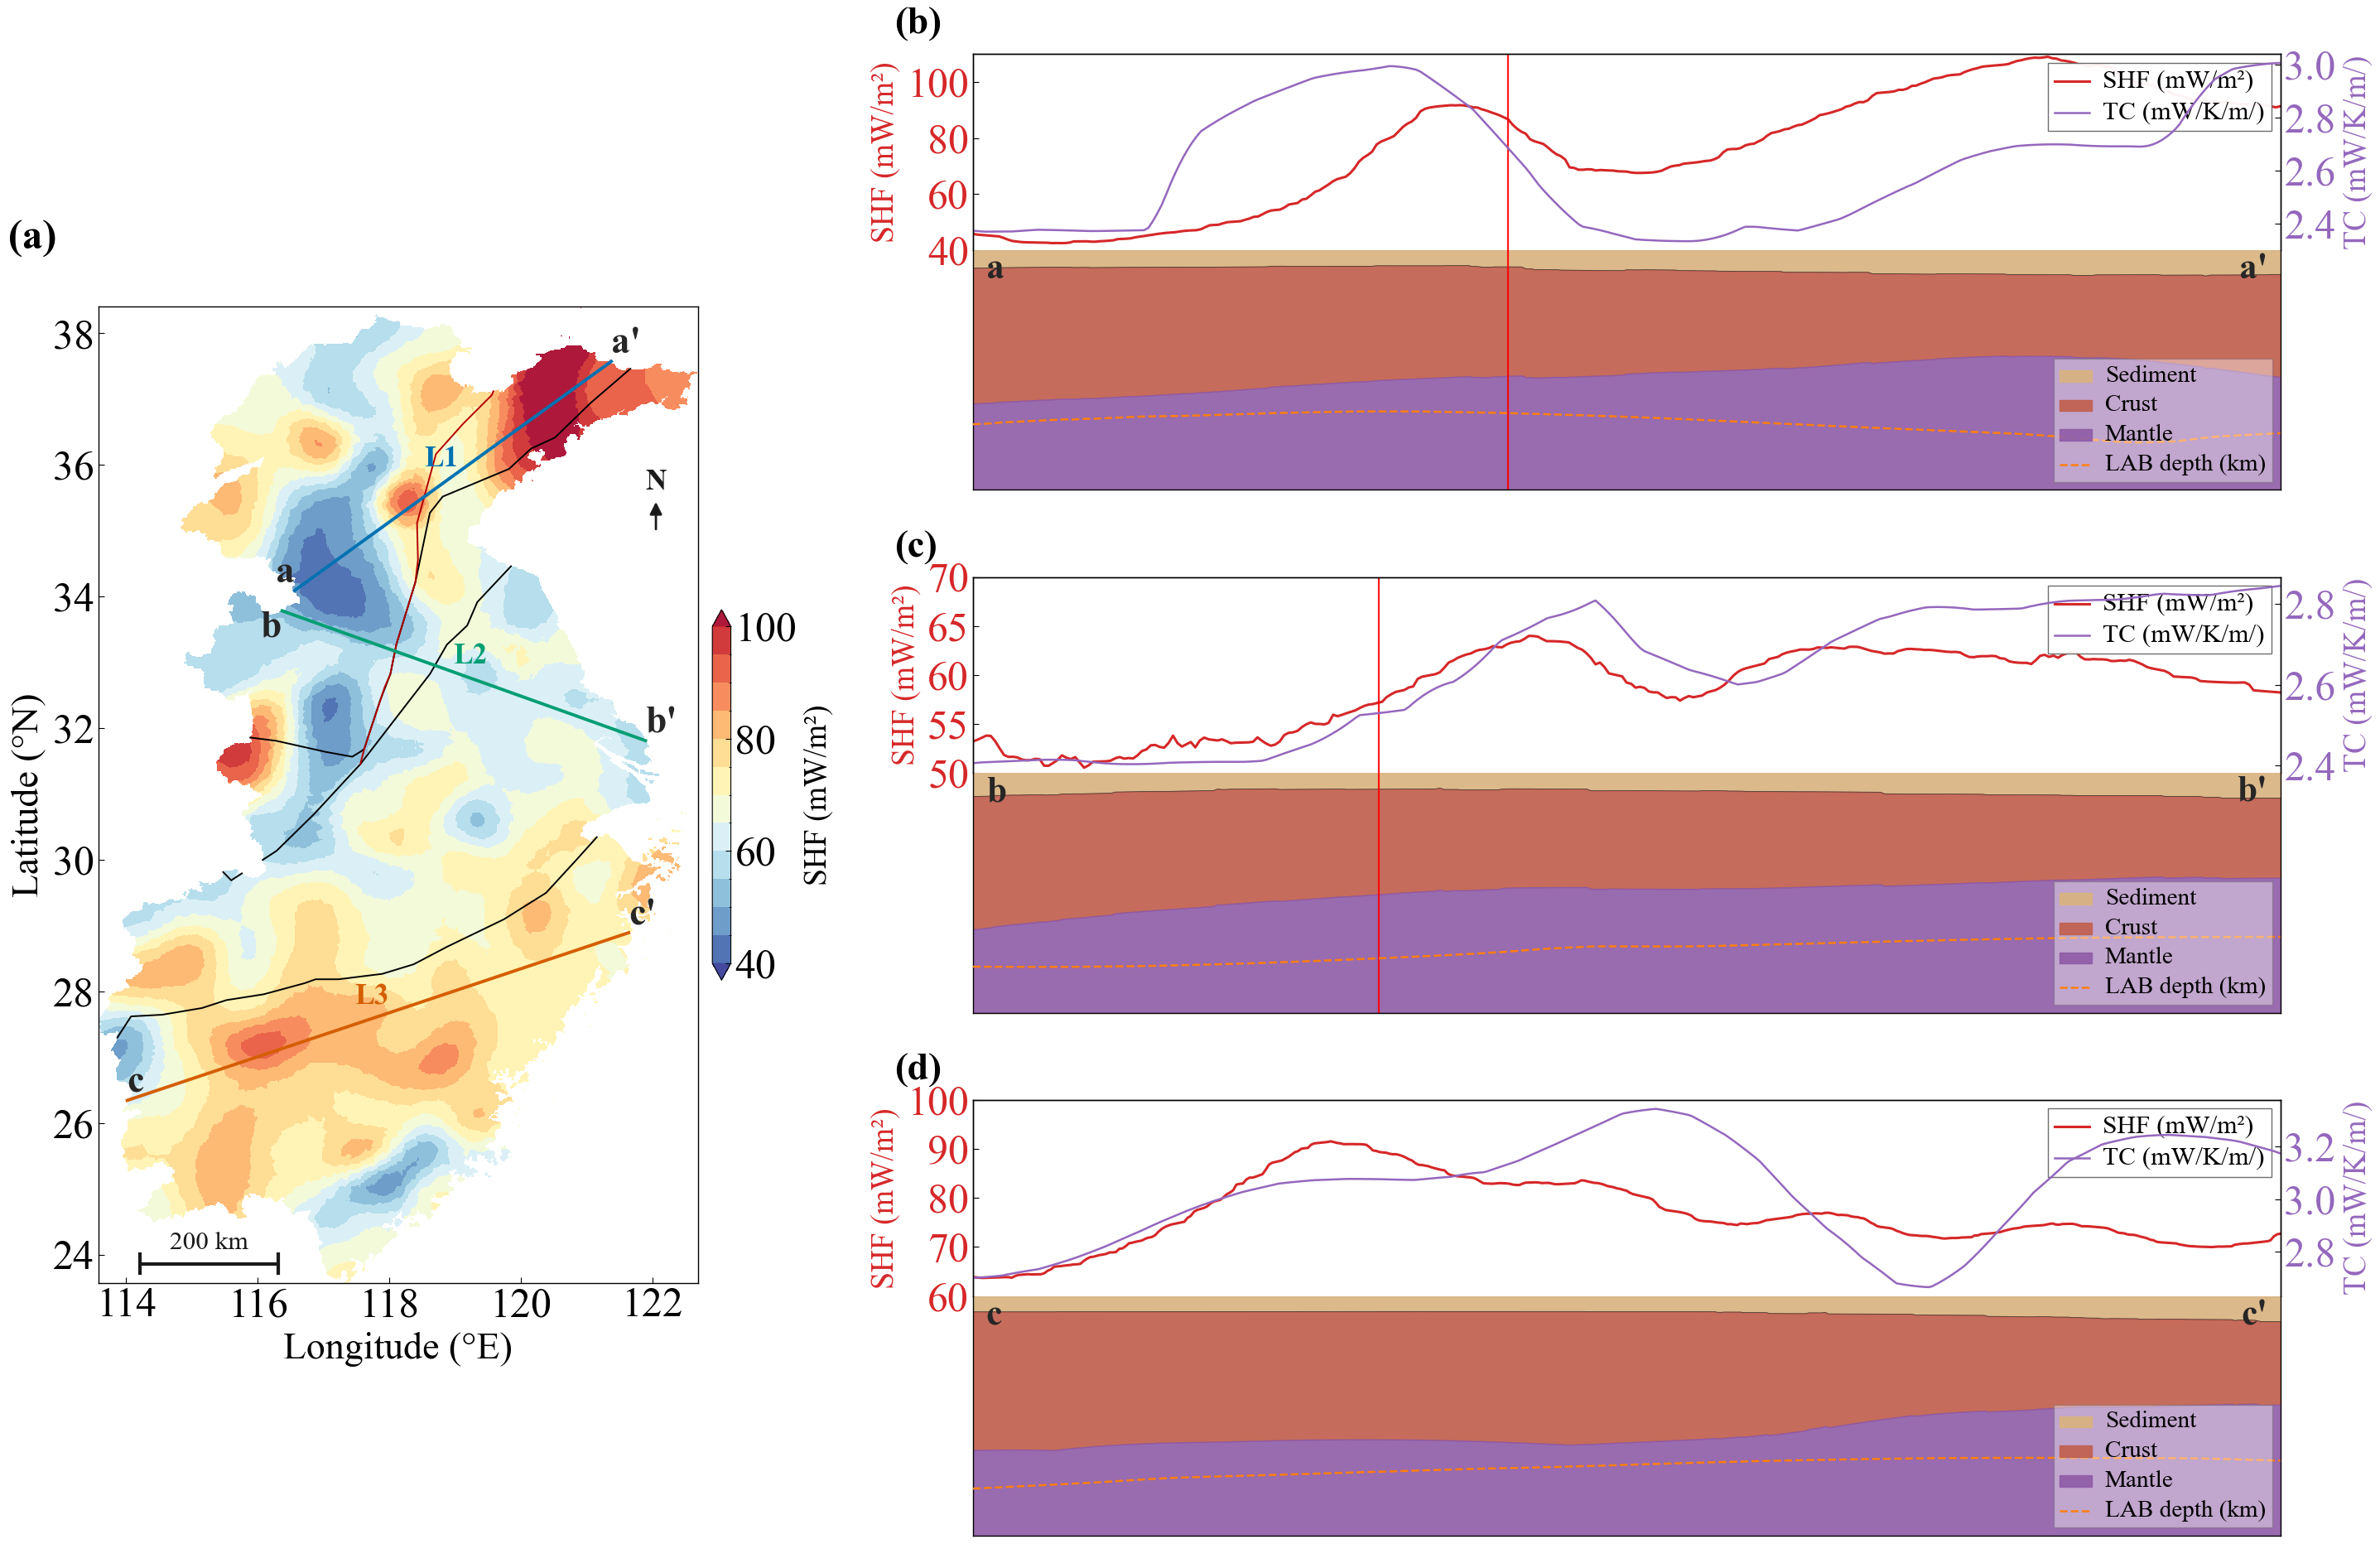

In [3]:
# 组合图：左列共享预测栅格底图（L2/L3/L7 三条剖面线，标 1/2/3、端点 a/a'、b/b'、c/c'）+ 右侧三条剖面
from PIL import Image

# 大图保存放宽 PIL 解压炸弹限制
Image.MAX_IMAGE_PIXELS = None

data = load_analysis_data()
render_combo_figure([2, 3, 7], data, out_name="combined_L2_L3_L7.png");


118°E 剖面线: 经度 118.0°E, 轮廓内纬度范围约 [24.45, 38.20]°N
采样点: 689 个, 剖面长度约 1526.2 km
双线性插值完成: {'vp6': 6.129, 'vp7': 6.421, 'vp8': 6.838}
灰白地形底图: (761, 534)


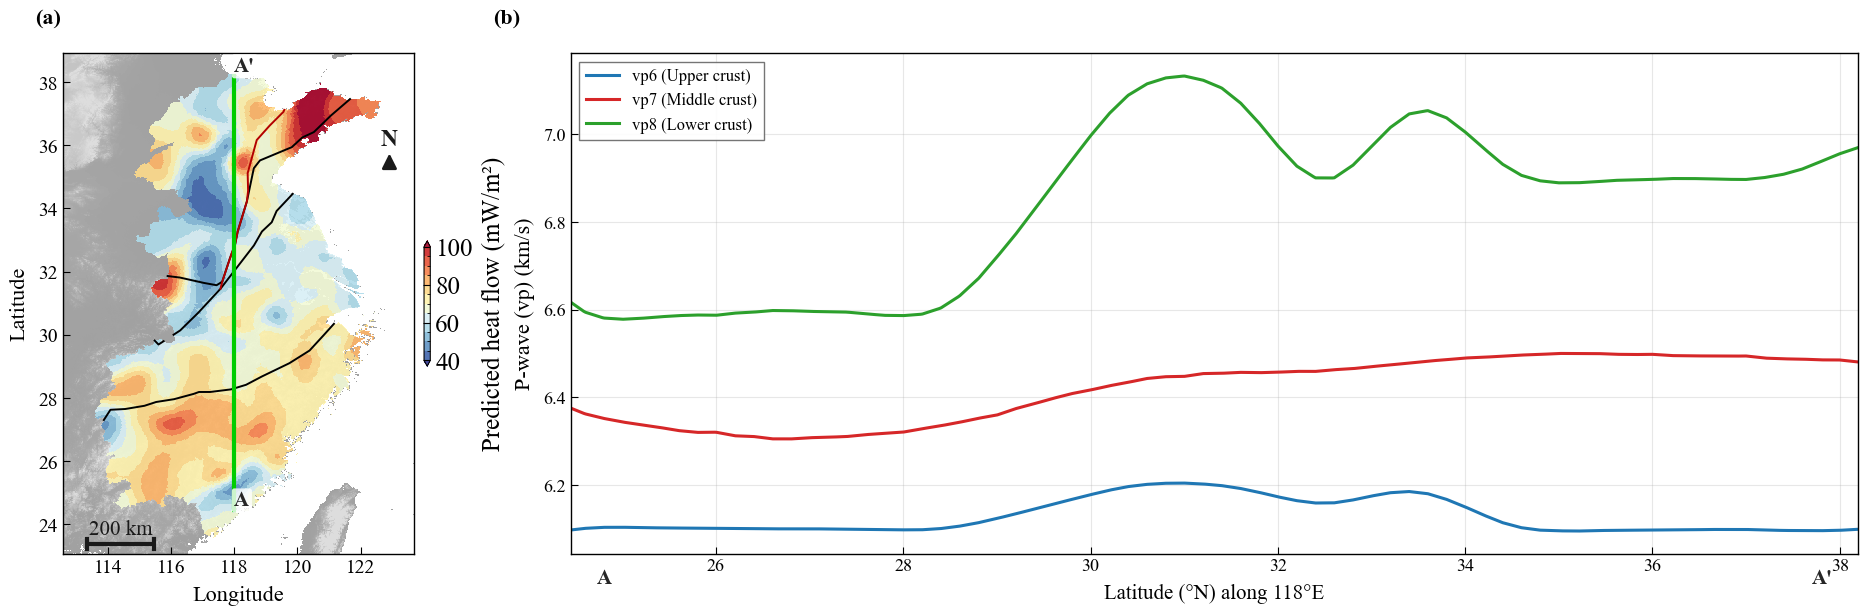

Saved plot: C:\KAN-OLS-SHF\output\analysis_line_profiles\L118E_meridian_vp.png
Saved profile CSV: C:\KAN-OLS-SHF\output\analysis_line_profiles\L118E_meridian_vp.csv


In [4]:
# ==================== 118°E 经线竖向剖面：ro/vp/vs 分层曲线（不绘制地壳结构） ====================
# 沿 118°E 经线竖向切一刀，取轮廓线内部分作为剖面线；
# 用双线性插值把 grid_0.2deg.xlsx 的 ro6-8 / vp6-8 / vs6-8 插到剖面，绘制 3 组曲线（无地壳结构面板）。
# 横坐标显示纬度值（°N）。

from shapely.geometry import LineString

PROFILE_LON = 118.0                       # 目标经线
PROP_GROUPS = {                           # 属性分组：(面板名, 单位, 列名列表)
    'P-wave (vp)':  ('km/s',  ['vp6', 'vp7', 'vp8']),
}
LAYER_LABELS = ['Upper crust', 'Middle crust', 'Lower crust']
LAYER_COLORS = ['#1f77b4', '#d62728', '#2ca02c']

# ---- 1) 加载数据与掩膜，构建 118°E 剖面线（轮廓内部分）----
data = load_analysis_data()
mask_poly = data['mask_poly']
if mask_poly is None:
    raise ValueError('未找到掩膜多边形，无法构建剖面线')

_xmin, ymin, _xmax, ymax = mask_poly.bounds
_meridian = LineString([(PROFILE_LON, ymin - 0.05), (PROFILE_LON, ymax + 0.05)])
clipped_line = clip_line_to_mask(_meridian, mask_poly)
sample_geom = longest_line(clipped_line)
if sample_geom is None:
    raise ValueError(f'经线 {PROFILE_LON}°E 与轮廓无交集')
print(f"118°E 剖面线: 经度 {PROFILE_LON}°E, 轮廓内纬度范围约 [{sample_geom.bounds[1]:.2f}, {sample_geom.bounds[3]:.2f}]°N")

# ---- 2) 沿线采样 ----
prof = sample_line_points(sample_geom, step_deg=0.02)
dist = prof['distance_km'].to_numpy()
lat_vals = prof['lat'].to_numpy()          # 横坐标：纬度（°N）
xi = prof[['lon', 'lat']].to_numpy(dtype=float)
print(f"采样点: {len(prof)} 个, 剖面长度约 {dist[-1]:.1f} km")

# ---- 3) 双线性插值 vp 到剖面 ----
grid_xls_df = pd.read_excel(grid_xls)

def _bilinear_for(col):
    sub = grid_xls_df.dropna(subset=['Longitude', 'Latitude', col]).copy()
    sub['lon'] = pd.to_numeric(sub['Longitude'], errors='coerce')
    sub['lat'] = pd.to_numeric(sub['Latitude'], errors='coerce')
    sub[col] = pd.to_numeric(sub[col], errors='coerce')
    sub = sub.dropna(subset=['lon', 'lat', col])
    _lons, _lats, _vals = build_regular_grid(sub, 'lon', 'lat', col)
    return build_bilinear_interpolator(_lons, _lats, _vals)

prop_interp = {col: _bilinear_for(col) for _u, cols in PROP_GROUPS.values() for col in cols}
prop_vals = {col: prop_interp[col](xi) for col in prop_interp}
print('双线性插值完成:', {c: round(float(np.nanmean(v)), 3) for c, v in prop_vals.items()})

# ---- 4) 绘图：左图(地形+热流+118°E线) + 右侧 vp 曲线面板 ----
lons = data['lons']; lats = data['lats']
lon_mesh, lat_mesh = np.meshgrid(lons, lats)

fig = plt.figure(figsize=(24, 6.5))
gs = fig.add_gridspec(1, 2, width_ratios=[0.7, 1.8], height_ratios=[1],
                      hspace=0.35, wspace=0.08)

# 左图：灰-白地形 + 热流栅格 + 构造线 + 118°E 剖面线
ax_map = fig.add_subplot(gs[:, 0])
shf_levels = np.arange(40, 101, 5)
shf_norm = BoundaryNorm(shf_levels, ncolors=256, extend='both')
draw_gray_terrain(ax_map, lons.min(), lons.max(), lats.min(), lats.max())
mesh = ax_map.pcolormesh(lon_mesh, lat_mesh, data['grid_vals_masked'],
                         cmap='RdYlBu_r', norm=shf_norm, shading='auto', alpha=0.9, zorder=1)
cb = fig.colorbar(mesh, ax=ax_map, label='Predicted heat flow (mW/m²)',
                  ticks=np.arange(40, 101, 20), extend='both', shrink=0.25, pad=0.02)
cb.outline.set_linewidth(0.8)
_tb = data.get('tb_map_geom')
if _tb is not None: plot_geom(ax_map, _tb, color='black', lw=1.4)
_fault = data.get('tlf_map_geom')
if _fault is not None: plot_geom(ax_map, _fault, color='#B30000', lw=1.4)
plot_geom(ax_map, sample_geom, color='#00CC00', lw=3.0)   # 118°E 剖面线：绿色
ax_map.set_xlabel('Longitude', fontsize=16)
ax_map.set_ylabel('Latitude', fontsize=16)
ax_map.tick_params(labelsize=14)
ax_map.set_aspect('equal')
add_north_arrow(ax_map)
add_scale_bar(ax_map, lat0=float(np.mean(lats)), length_km=200)
ax_map.text(-0.08, 1.05, '(a)', transform=ax_map.transAxes, fontsize=16,
            fontweight='bold', va='bottom', ha='left', clip_on=False)
# 118°E 线两端标注 A（南/起点）/ A'（北/终点），表明绘制方向
_c118 = np.asarray(sample_geom.coords)
for (_px, _py), _lab in [((_c118[0, 0], _c118[0, 1]), 'A'),
                         ((_c118[-1, 0], _c118[-1, 1]), "A'")]:
    ax_map.text(_px, _py, _lab, fontsize=15, fontweight='bold', color='0.15',
                ha='left', va='bottom', zorder=4,
                bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.8))

# 右侧 vp 曲线面板（layer 6/7/8 三条曲线，共用 x 轴 = 纬度）
axs_curve = []
for row, (grp, (unit, cols)) in enumerate(PROP_GROUPS.items()):
    ax = fig.add_subplot(gs[row, 1], sharex=axs_curve[0] if axs_curve else None)
    axs_curve.append(ax)
    for ci, col in enumerate(cols):
        ax.plot(lat_vals, prop_vals[col], color=LAYER_COLORS[ci], linewidth=2.2,
                label=f'{col} ({LAYER_LABELS[ci]})')
    ax.set_ylabel(f'{grp} ({unit})', fontsize=16)
    ax.tick_params(labelsize=13)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=12, loc='upper left', framealpha=0.9)
    ax.text(-0.06, 1.05, f'({chr(98 + row)})', transform=ax.transAxes, fontsize=16,
            fontweight='bold', va='bottom', ha='left', clip_on=False)
for ax in axs_curve[:-1]:
    ax.tick_params(axis='x', labelbottom=False)
axs_curve[-1].set_xlabel('Latitude (°N) along 118°E', fontsize=15)
axs_curve[0].set_xlim(lat_vals.min(), lat_vals.max())
# 右图两端标注 A（低纬/起点）/ A'（高纬/终点），移到 x 轴下方、绘图框外
axs_curve[0].text(0.02, -0.03, 'A', transform=axs_curve[0].transAxes, ha='left', va='top',
                  fontsize=15, fontweight='bold', color='0.15', clip_on=False)
axs_curve[0].text(0.98, -0.03, "A'", transform=axs_curve[0].transAxes, ha='right', va='top',
                  fontsize=15, fontweight='bold', color='0.15', clip_on=False)

# 不用 tight_layout：它会因等比例地图面板导致两轴盒高度不一致，从而子图编号无法对齐
out_118 = out_dir / 'L118E_meridian_vp.png'
fig.savefig(out_118, dpi=1000, bbox_inches='tight')
plt.show()
print(f"Saved plot: {out_118}")

# ---- 5) 保存剖面数据 CSV（含 vp 曲线）----
csv_df = prof[['lon', 'lat', 'distance_km']].copy()
for col, vals in prop_vals.items():
    csv_df[col] = vals
csv_118 = out_dir / 'L118E_meridian_vp.csv'
csv_df.to_csv(csv_118, index=False)
print(f"Saved profile CSV: {csv_118}")

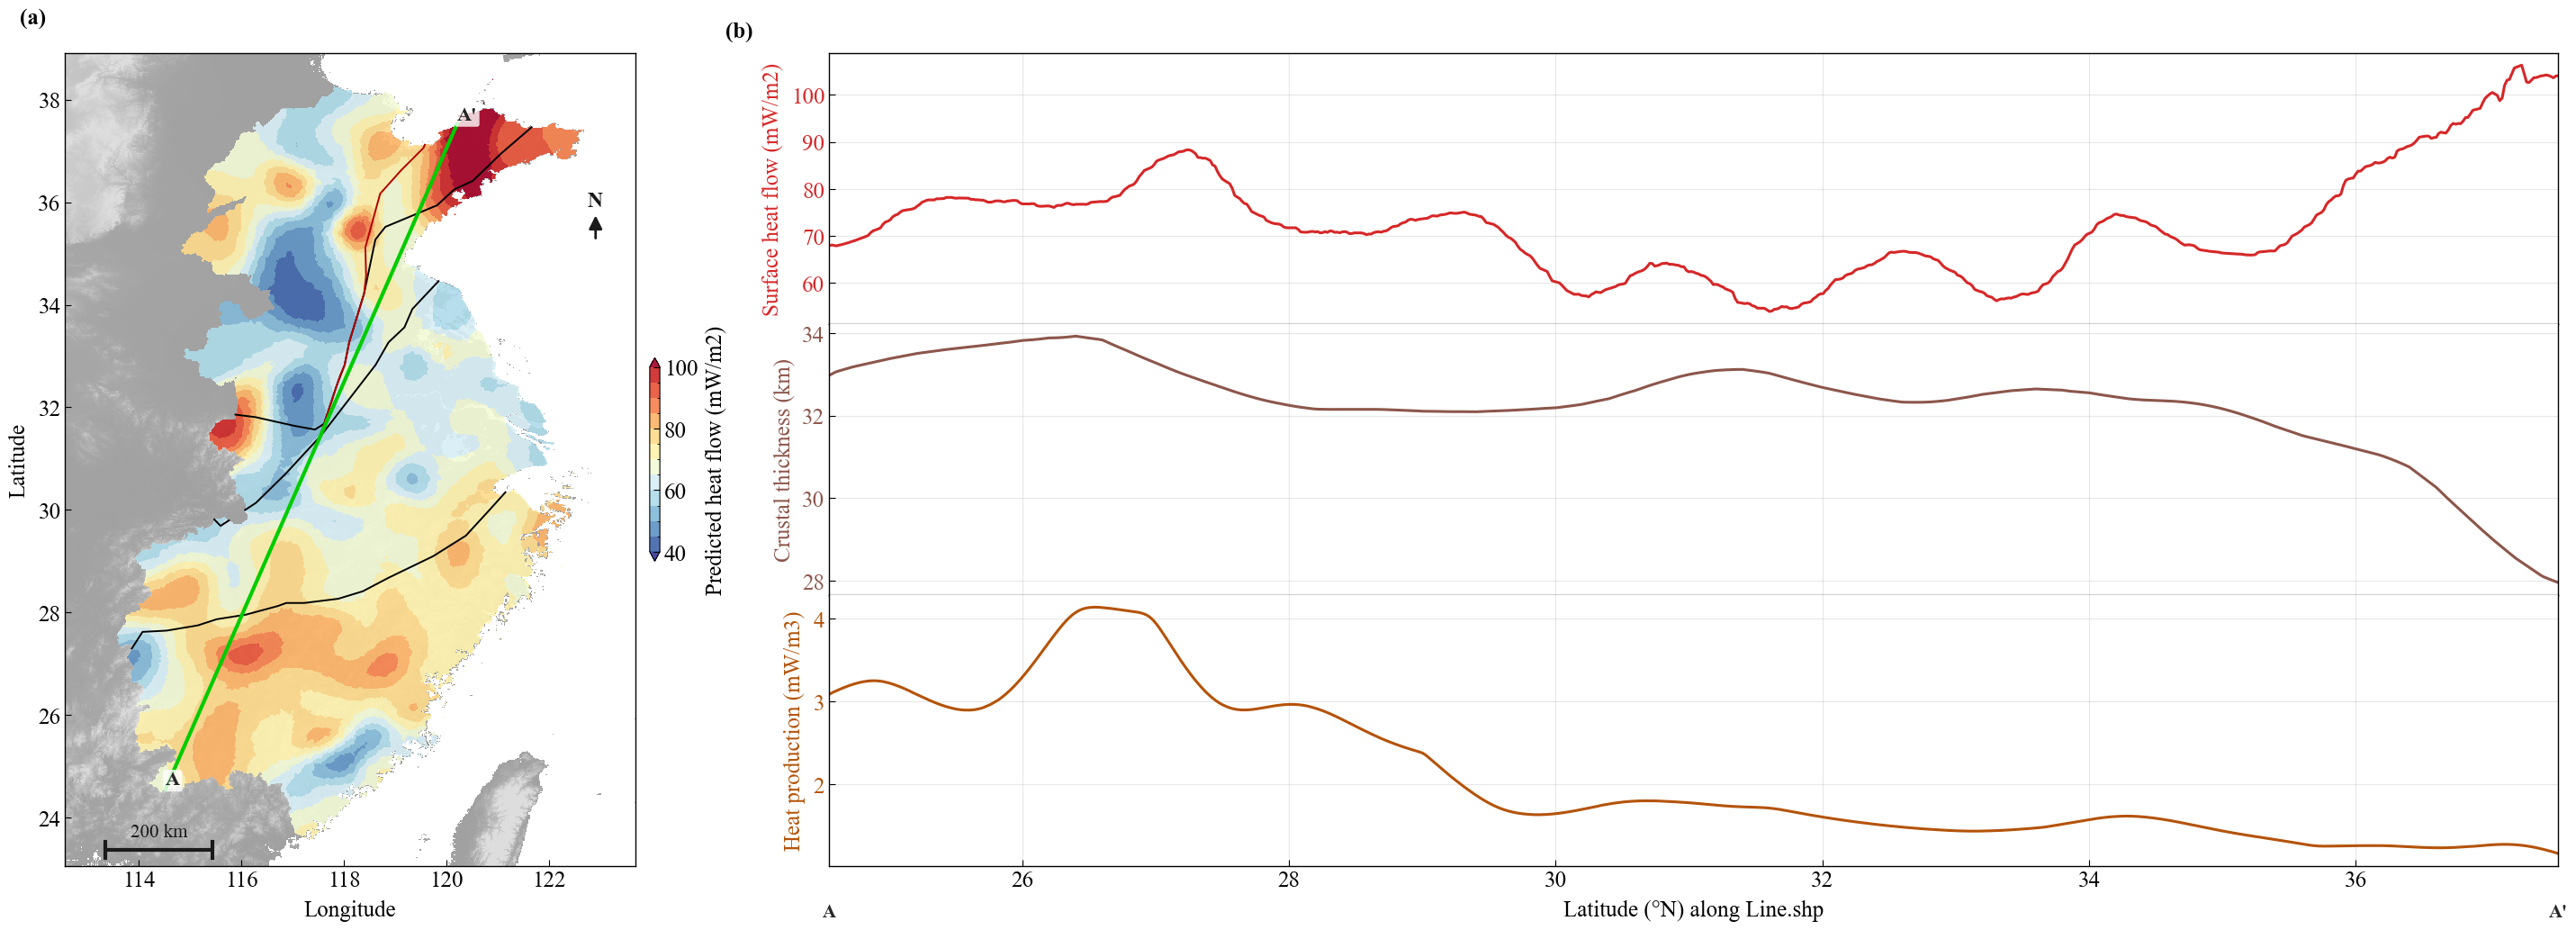

Saved plot: C:\KAN-OLS-SHF\output\analysis_line_profiles\Line_heat_thickness_heatproduction.png
Saved profile CSV: C:\KAN-OLS-SHF\output\analysis_line_profiles\Line_heat_thickness_heatproduction.csv


In [5]:
# ==================== Line.shp：热流 + 地壳厚度 + 生热率剖面图 ====================
# 左图：Line.shp 裁剪后的预测热流栅格与剖面线；右图：三条独立但上下贴合的剖面曲线。
# 横坐标统一使用纬度（°N），起点为 A，终点为 A'。

LINE_PROFILE_SHP = line_dir / "Line.shp"
CRUST_THICKNESS_COL = "crsthk"

# ---- 1) 读取 Line.shp，裁剪到研究区并沿线采样 ----
data = load_analysis_data()
mask_poly = data["mask_poly"]
if mask_poly is None:
    raise ValueError("未找到掩膜多边形，无法构建 Line.shp 剖面线")
if not LINE_PROFILE_SHP.exists():
    raise FileNotFoundError(f"Line.shp not found: {LINE_PROFILE_SHP}")

line_gdf = read_line_gdf(LINE_PROFILE_SHP)
line_geom = unary_union(line_gdf.geometry[~line_gdf.geometry.is_empty])
clipped_line = clip_line_to_mask(line_geom, mask_poly)
sample_geom = longest_line(clipped_line)
if sample_geom is None:
    raise ValueError("Line.shp 裁剪后无有效剖面线段")

prof = sample_line_points(sample_geom, step_deg=0.02)
if prof.empty:
    raise ValueError("Line.shp 沿线采样失败")

xi = prof[["lon", "lat"]].to_numpy(dtype=float)
lat_vals = prof["lat"].to_numpy(dtype=float)          # 横坐标：纬度（°N）

# ---- 2) 三类属性插值 ----
# 地表热流：预测栅格插值；地壳厚度：grid_0.2deg.xlsx 双线性插值；生热率：克里金插值。
heat_vals = np.asarray(data["interp_grid"](xi), dtype=float)
hp_vals = np.asarray(data["interp_hp"](xi), dtype=float)

grid_xls_df = pd.read_excel(grid_xls)
if CRUST_THICKNESS_COL not in grid_xls_df.columns:
    raise KeyError(
        f"{grid_xls.name} 中未找到地壳厚度列 {CRUST_THICKNESS_COL!r}；"
        f"可用列包括: {list(grid_xls_df.columns)}"
    )

thickness_sub = grid_xls_df.dropna(
    subset=["Longitude", "Latitude", CRUST_THICKNESS_COL]
).copy()
thickness_sub["lon"] = pd.to_numeric(thickness_sub["Longitude"], errors="coerce")
thickness_sub["lat"] = pd.to_numeric(thickness_sub["Latitude"], errors="coerce")
thickness_sub[CRUST_THICKNESS_COL] = pd.to_numeric(
    thickness_sub[CRUST_THICKNESS_COL], errors="coerce"
)
thickness_sub = thickness_sub.dropna(
    subset=["lon", "lat", CRUST_THICKNESS_COL]
)
if thickness_sub.empty:
    raise ValueError(f"{grid_xls.name} 中没有可用于 {CRUST_THICKNESS_COL} 插值的有效数据")

th_lons, th_lats, th_values = build_regular_grid(
    thickness_sub, "lon", "lat", CRUST_THICKNESS_COL
)
interp_thickness = build_bilinear_interpolator(th_lons, th_lats, th_values)
thickness_vals = np.asarray(interp_thickness(xi), dtype=float)

# ---- 3) 绘图：左侧地图 + 右侧三个上下贴合的曲线面板 ----
lons = data["lons"]
lats = data["lats"]
lon_mesh, lat_mesh = np.meshgrid(lons, lats)

fig = plt.figure(figsize=(30, 10.5))
gs = fig.add_gridspec(
    3, 2, width_ratios=[0.82, 2.0], height_ratios=[1, 1, 1],
    hspace=0.0, wspace=0.06
)
ax_map = fig.add_subplot(gs[:, 0])
ax_heat = fig.add_subplot(gs[0, 1])
ax_thickness = fig.add_subplot(gs[1, 1], sharex=ax_heat)
ax_hp = fig.add_subplot(gs[2, 1], sharex=ax_heat)

# 左图：灰白地形、预测热流栅格、构造线和 Line.shp 剖面线。
shf_levels = np.arange(40, 101, 5)
shf_norm = BoundaryNorm(shf_levels, ncolors=256, extend="both")
draw_gray_terrain(ax_map, lons.min(), lons.max(), lats.min(), lats.max())
mesh = ax_map.pcolormesh(
    lon_mesh, lat_mesh, data["grid_vals_masked"],
    cmap="RdYlBu_r", norm=shf_norm, shading="auto", alpha=0.9, zorder=1
)
cb = fig.colorbar(
    mesh, ax=ax_map, label="Predicted heat flow (mW/m2)",
    ticks=np.arange(40, 101, 20), extend="both", shrink=0.25, pad=0.02
)
cb.outline.set_linewidth(0.8)

_tb = data.get("tb_map_geom")
if _tb is not None:
    plot_geom(ax_map, _tb, color="black", lw=1.4)
_fault = data.get("tlf_map_geom")
if _fault is not None:
    plot_geom(ax_map, _fault, color="#B30000", lw=1.4)
plot_geom(ax_map, sample_geom, color="#00CC00", lw=3.0)
add_north_arrow(ax_map)
add_scale_bar(ax_map, lat0=float(np.mean(lats)), length_km=200)
ax_map.set_xlabel("Longitude")
ax_map.set_ylabel("Latitude")
ax_map.set_aspect("equal")
ax_map.text(-0.08, 1.03, "(a)", transform=ax_map.transAxes,
            fontsize=18, fontweight="bold", va="bottom", ha="left", clip_on=False)

line_coords = np.asarray(sample_geom.coords)
for (px, py), label in [
    ((line_coords[0, 0], line_coords[0, 1]), "A"),
    ((line_coords[-1, 0], line_coords[-1, 1]), "A'"),
]:
    ax_map.text(
        px, py, label, fontsize=16, fontweight="bold", color="0.15",
        ha="left", va="bottom", zorder=4,
        bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8)
    )

# 右图：三条曲线使用纬度（°N）作横坐标，上下贴合；
# 三个面板均绘制坐标线（水平+垂直，垂直线跨面板对齐纬度），最下面面板标注纬度刻度。
curve_specs = [
    (ax_heat, lat_vals, heat_vals, "Surface heat flow (mW/m2)", "tab:red", "(b)"),
    (ax_thickness, lat_vals, thickness_vals, "Crustal thickness (km)", "#8C564B", ""),
    (ax_hp, lat_vals, hp_vals, "Heat production (mW/m3)", "#B45309", ""),
]
for ax, x_values, y_values, ylabel, color, panel_label in curve_specs:
    ax.plot(x_values, y_values, color=color, linewidth=2.2)
    ax.set_ylabel(ylabel, color=color)
    ax.tick_params(axis="y", labelcolor=color)
    ax.grid(True, alpha=0.3)   # 三个面板都有坐标线
    ax.text(-0.06, 1.04, panel_label, transform=ax.transAxes,
            fontsize=18, fontweight="bold", va="bottom", ha="left", clip_on=False)
    ax.tick_params(axis="x", which="both", bottom=False, labelbottom=False)

# 三个面板都保留底脊；仅隐藏相邻下方面板的顶脊，避免同一位置出现双重分割线；
# 最上面面板保留顶脊（整图顶边），最下面面板保留底脊（整图底边）。
ax_hp.spines["top"].set_visible(False)
ax_thickness.spines["top"].set_visible(False)
ax_hp.tick_params(axis="x", which="both", bottom=True, labelbottom=True)
ax_hp.set_xlabel("Latitude (°N) along Line.shp")
ax_heat.set_xlim(lat_vals.min(), lat_vals.max())
# 最下面面板显示纬度刻度；A/A' 标注在底部 x 轴两端下方外侧（与地图方向一致）
_ylim = ax_hp.get_ylim()
_yrng = max(_ylim[1] - _ylim[0], 1e-9)
ax_hp.text(float(lat_vals[0]), _ylim[0] - 0.14 * _yrng, "A",
           ha="center", va="top", fontsize=15, fontweight="bold",
           color="0.15", clip_on=False)
ax_hp.text(float(lat_vals[-1]), _ylim[0] - 0.14 * _yrng, "A'",
           ha="center", va="top", fontsize=15, fontweight="bold",
           color="0.15", clip_on=False)

fig.subplots_adjust(top=0.96, bottom=0.10, left=0.05, right=0.98)
out_line_curves = out_dir / "Line_heat_thickness_heatproduction.png"
fig.savefig(out_line_curves, dpi=600, bbox_inches="tight")
plt.show()
print(f"Saved plot: {out_line_curves}")

# 保存三条曲线对应的剖面数据，便于后续制图或数值分析。
line_curve_df = prof[["lon", "lat", "distance_km"]].copy()
line_curve_df["SHF_pred"] = heat_vals
line_curve_df["crust_thickness_km"] = thickness_vals
line_curve_df["heat_production"] = hp_vals
out_line_curve_csv = out_dir / "Line_heat_thickness_heatproduction.csv"
line_curve_df.to_csv(out_line_curve_csv, index=False)
print(f"Saved profile CSV: {out_line_curve_csv}")